# Project Title: Anomaly Detection for Healthcare Cloud Database Systems using Random Forest and SHAP


# Import Library

In [ ]:
import os
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve,
    matthews_corrcoef, balanced_accuracy_score)

from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

/opt/conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Authentication process

Kaggle requires credentials from users who are downloading this dataset with an API token from Kaggle.

In [ ]:
!mkdir -p ~/.kaggle && echo KGAT_b8548c767288b53955e50f04d8875441 > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

!python -m kaggle competitions list

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

# Download and unzip the dataset

All 13.9M of the dataset was downloaded successfully.

In [ ]:
!python -m kaggle datasets download -d hassan06/nslkdd -p ./kaggle_download --unzip

for root, dirs, files in os.walk("./kaggle_download"):
    for f in files:
        print(os.path.join(root, f))

Dataset URL: https://www.kaggle.com/datasets/hassan06/nslkdd
License(s): unknown
100%|██████████████████████████████████████| 13.9M/13.9M [00:00<00:00, 16.5MB/s]

./kaggle_download/KDDTrain1.jpg
./kaggle_download/KDDTrain+_20Percent.txt
./kaggle_download/KDDTest+.arff
./kaggle_download/KDDTest1.jpg
./kaggle_download/KDDTest-21.arff
./kaggle_download/index.html
./kaggle_download/KDDTest+.txt
./kaggle_download/KDDTest-21.txt
./kaggle_download/KDDTrain+.txt
./kaggle_download/KDDTrain+_20Percent.arff
./kaggle_download/KDDTrain+.arff
./kaggle_download/nsl-kdd/KDDTrain1.jpg
./kaggle_download/nsl-kdd/KDDTrain+_20Percent.txt
./kaggle_download/nsl-kdd/KDDTest+.arff
./kaggle_download/nsl-kdd/KDDTest1.jpg
./kaggle_download/nsl-kdd/KDDTest-21.arff
./kaggle_download/nsl-kdd/index.html
./kaggle_download/nsl-kdd/KDDTest+.txt
./kaggle_download/nsl-kdd/KDDTest-21.txt
./kaggle_download/nsl-kdd/KDDTrain+.txt
./kaggle_download/nsl-kdd/KDDTrain+_20Percent.arff
./kaggle_download/nsl-kdd/KDDTrain+.arff


# Load Train and Test Datasets
This cell loads and reads the shape of KDDTrain and KDDTest, preparing it for analysis.

In [ ]:
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_df = pd.read_csv("./kaggle_download/KDDTrain+.txt", names=columns)
test_df = pd.read_csv("./kaggle_download/KDDTest+.txt", names=columns)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (125973, 43)
Test shape: (22544, 43)


# Data Cleaning
In this cell, the column difficulty is removed as it is not a feature of the dataset. Both train and test datasets have 0 duplicates and missing values. The data types include int64 (23), float64 (15), object (4) and overall 42 collumns.

In [ ]:
train_df = train_df.drop(columns=["difficulty"])
test_df = test_df.drop(columns=["difficulty"])

print("Train duplicates:", train_df.duplicated().sum())
print("Test duplicates:", test_df.duplicated().sum())

print("\nTrain missing values:", train_df.isna().sum().sum())
print("Test missing values:", test_df.isna().sum().sum())

print("\nTrain dtypes:\n", train_df.dtypes.value_counts())

Train duplicates: 0
Test duplicates: 0

Train missing values: 0
Test missing values: 0

Train dtypes:
 int64      23
float64    15
object      4
Name: count, dtype: int64


# Label Engineering

This cell changes the multi-class attack labels into binary labels (attack or normal) and displays the class imbalance in both test and train datasets.

In [ ]:
train_df["binary_label"] = train_df["label"].apply(lambda x: "normal" if x == "normal" else "attack")
test_df["binary_label"] = test_df["label"].apply(lambda x: "normal" if x == "normal" else "attack")

print("Train binary label distribution:")
print(train_df["binary_label"].value_counts())

print("\nTest binary label distribution:")
print(test_df["binary_label"].value_counts())

Train binary label distribution:
binary_label
normal    67343
attack    58630
Name: count, dtype: int64

Test binary label distribution:
binary_label
attack    12833
normal     9711
Name: count, dtype: int64


# EDA 1: Class Imbalance
This cell visualises is the classes attack and normal are balanced in the test and train datasets.

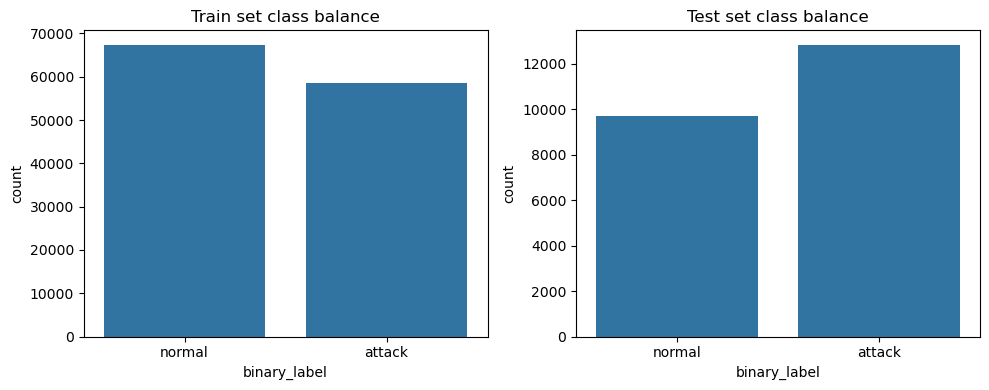

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(x="binary_label", data=train_df, ax=axes[0], order=["normal", "attack"])
axes[0].set_title("Train set class balance")

sns.countplot(x="binary_label", data=test_df, ax=axes[1], order=["normal", "attack"])
axes[1].set_title("Test set class balance")

plt.tight_layout()
plt.show()

# EDA 2: Feature Distribution
This cell visualises how much the categories protocol_type, flag and service appear in the train dataset.

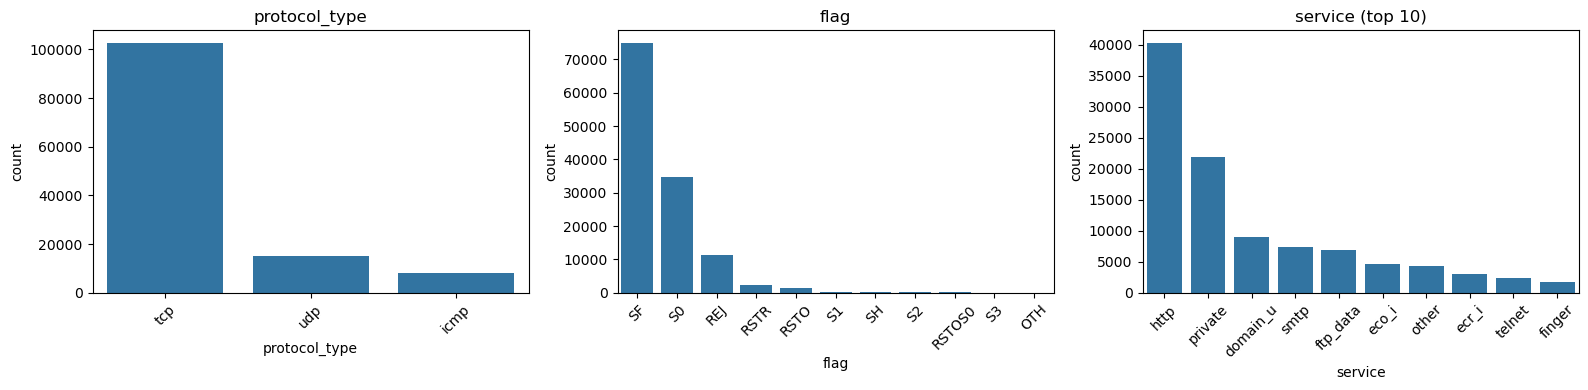

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x="protocol_type", data=train_df, ax=axes[0], order=train_df["protocol_type"].value_counts().index)
axes[0].set_title("protocol_type")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(x="flag", data=train_df, ax=axes[1], order=train_df["flag"].value_counts().index)
axes[1].set_title("flag")
axes[1].tick_params(axis="x", rotation=45)

top_services = train_df["service"].value_counts().head(10).index
sns.countplot(x="service", data=train_df[train_df["service"].isin(top_services)], ax=axes[2], order=top_services)
axes[2].set_title("service (top 10)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# EDA 3: Correlation Heatmap
This cell visualises the correlation between numerical values in the train dataset.

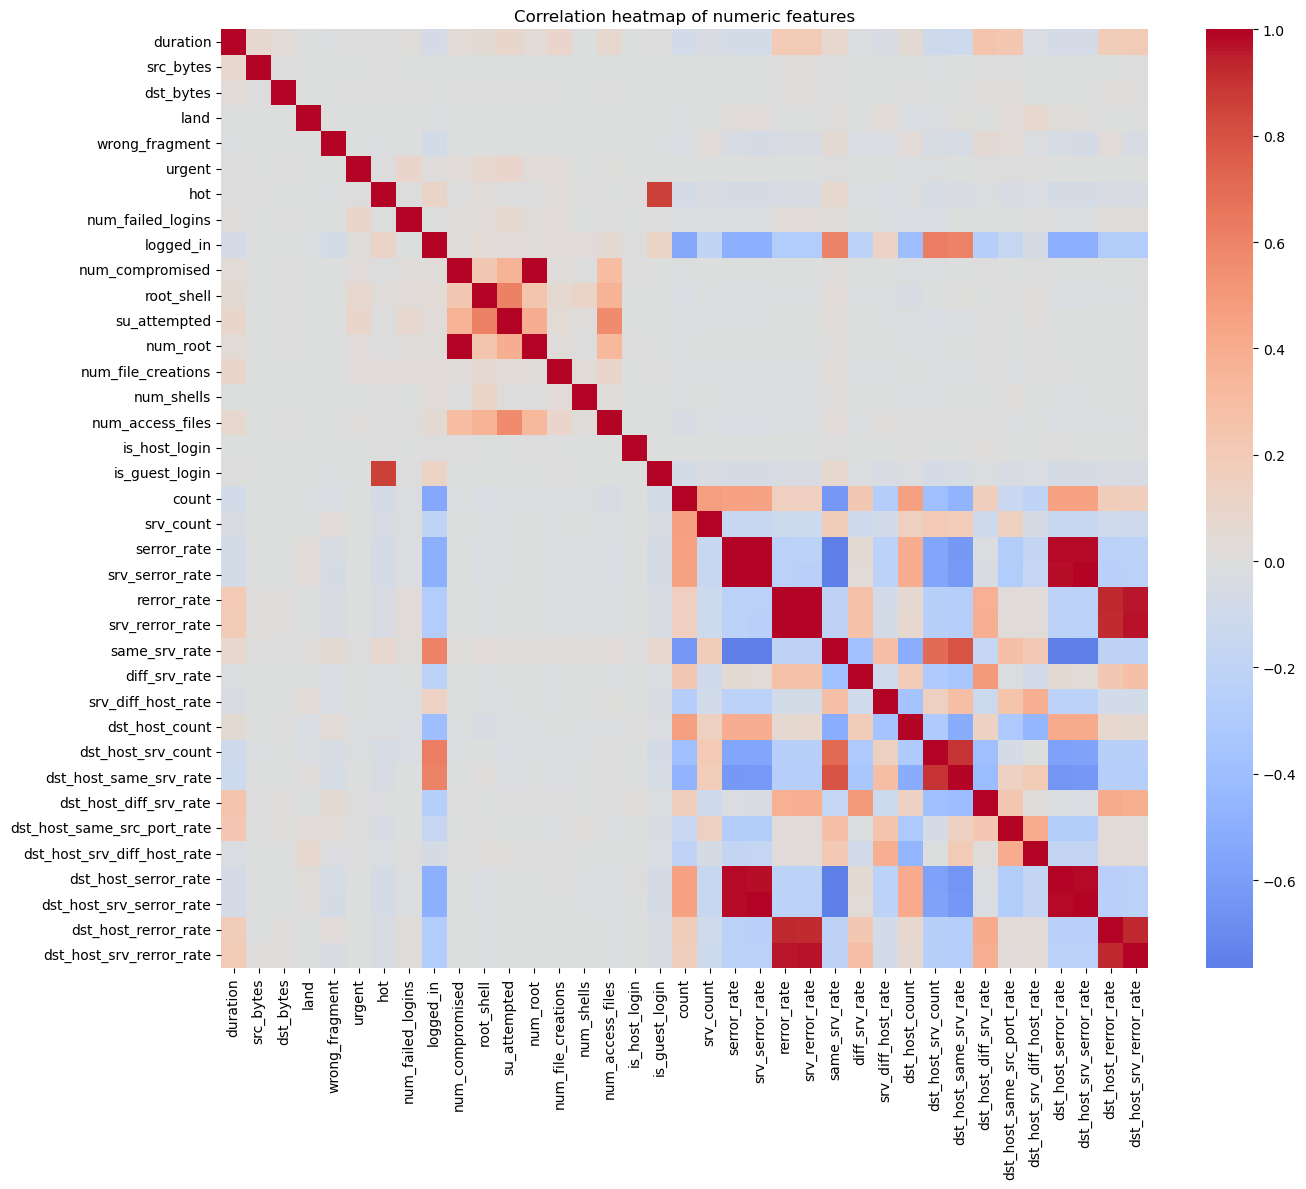

In [ ]:
numeric_cols = train_df.select_dtypes(include=["int64", "float64"]).columns
numeric_cols = [c for c in numeric_cols if train_df[c].nunique() > 1]

plt.figure(figsize=(14, 12))
sns.heatmap(train_df[numeric_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric features")
plt.tight_layout()
plt.show()

# Encoding
This cells uses label encoder to convert all three categories into numerical values.

In [ ]:
categorical_cols = ["protocol_type", "service", "flag"]
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    train_df[col] = le.fit_transform(train_df[col])

    known_classes = set(le.classes_)
    test_df[col] = test_df[col].apply(lambda x: le.transform([x])[0] if x in known_classes else -1)

    encoders[col] = le
    print(f"{col}: {len(le.classes_)} categories learned from train")

protocol_type: 3 categories learned from train
service: 70 categories learned from train
flag: 11 categories learned from train


# Data Splitting
This cell splits the KDDTrain dataset into 80% train and 20% valudation sets, using a stratified split.

In [ ]:
feature_cols = [c for c in train_df.columns if c not in ["label", "binary_label"]]

X = train_df[feature_cols]
y = train_df["binary_label"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

X_train shape: (100778, 41)
X_val shape: (25195, 41)


# Model Development
This cell finds the difference between attack and normal traffic in the dataset by training the Random Forest classifier on the 80% train set.

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

# Validation split
This cell uses the metrics accuracy, precision, recall and F1 to assess the trained model on the 20% validation set

In [ ]:
y_val_pred = rf_model.predict(X_val)

print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation Precision:", precision_score(y_val, y_val_pred, pos_label="attack"))
print("Validation Recall:", recall_score(y_val, y_val_pred, pos_label="attack"))
print("Validation F1:", f1_score(y_val, y_val_pred, pos_label="attack"))

Validation Accuracy: 0.9991268108751736
Validation Precision: 0.9994026284348865
Validation Recall: 0.9987207914037183
Validation F1: 0.9990615935847125


# Evalutation on Test dataset
This cell evaluates the KDDTest set using the performance metrics ROC curve, PR curve and confusion matrix.

Test AUROC: 0.963  |  Test AUPRC: 0.965
Accuracy: 0.771  Precision: 0.966  Recall: 0.620  F1: 0.755


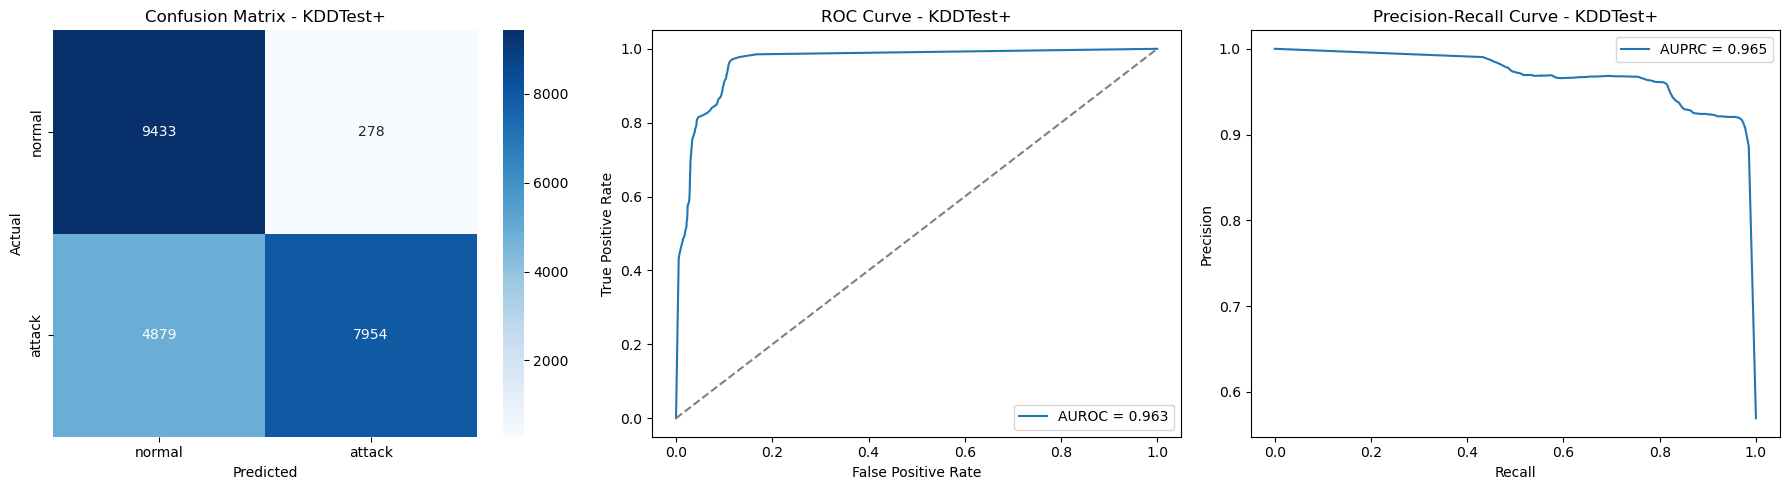

In [ ]:
X_test = test_df[feature_cols]
y_test = test_df["binary_label"]

y_test_pred = rf_model.predict(X_test)
attack_idx = list(rf_model.classes_).index("attack")
y_test_proba = rf_model.predict_proba(X_test)[:, attack_idx]
y_test_binary = (y_test == "attack").astype(int)

auroc = roc_auc_score(y_test_binary, y_test_proba)
auprc = average_precision_score(y_test, y_test_proba, pos_label="attack")
acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred, pos_label="attack")
rec = recall_score(y_test, y_test_pred, pos_label="attack")
f1 = f1_score(y_test, y_test_pred, pos_label="attack")

print(f"Test AUROC: {auroc:.3f}  |  Test AUPRC: {auprc:.3f}")
print(f"Accuracy: {acc:.3f}  Precision: {prec:.3f}  Recall: {rec:.3f}  F1: {f1:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm = confusion_matrix(y_test, y_test_pred, labels=["normal", "attack"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["normal", "attack"], yticklabels=["normal", "attack"], ax=axes[0])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion Matrix - KDDTest+")

fpr, tpr, _ = roc_curve(y_test, y_test_proba, pos_label="attack")
axes[1].plot(fpr, tpr, label=f"AUROC = {auroc:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve - KDDTest+")
axes[1].legend()

prec_c, rec_c, _ = precision_recall_curve(y_test, y_test_proba, pos_label="attack")
axes[2].plot(rec_c, prec_c, label=f"AUPRC = {auprc:.3f}")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve - KDDTest+")
axes[2].legend()

plt.tight_layout()
plt.show()

# False Positive Rate (FPR) and False Negative Rate (FNR)
This cell visualises the false positive rates (FPR) and false negative rate (FNR), which are measures used for intrusion detection systems (IDS).

False Positive Rate (FPR): 0.029
False Negative Rate (FNR): 0.380


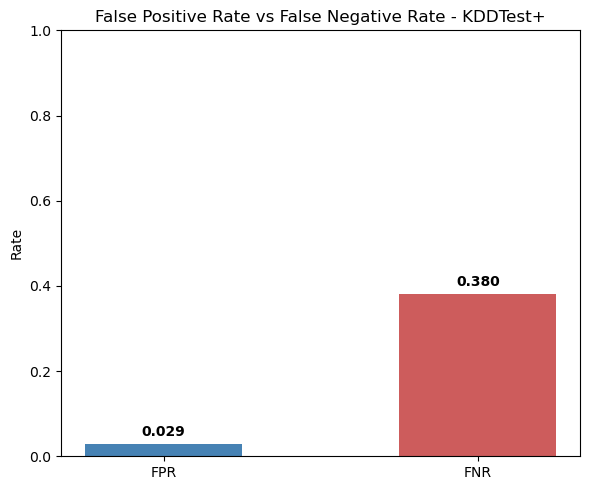

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred, labels=["normal", "attack"]).ravel()

fpr_rate = fp / (fp + tn)
fnr_rate = fn / (fn + tp)

print(f"False Positive Rate (FPR): {fpr_rate:.3f}")
print(f"False Negative Rate (FNR): {fnr_rate:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(["FPR", "FNR"], [fpr_rate, fnr_rate], color=["steelblue", "indianred"], width=0.5)
ax.set_ylim(0, 1)
ax.set_ylabel("Rate")
ax.set_title("False Positive Rate vs False Negative Rate - KDDTest+")

for bar, value in zip(bars, [fpr_rate, fnr_rate]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.3f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

# Matthews Correlation Coefficient (MCC) and Balanced accuray
This cell measures class imbalance by using Matthews Correlation Coefficient (MCC) and balanced accuracy, two metrics specifically used intrusion detection systems (IDS).

In [ ]:
mcc = matthews_corrcoef(y_test, y_test_pred)
bal_acc = balanced_accuracy_score(y_test, y_test_pred)

print(f"Matthews Correlation Coefficient (MCC): {mcc:.3f}")
print(f"Balanced Accuracy: {bal_acc:.3f}")

Matthews Correlation Coefficient (MCC): 0.608
Balanced Accuracy: 0.796


# Explainable AI (XAI): SHAP
This cell uses the global feature importance bar chart to visualise which feature causes Random Forest's predictions.

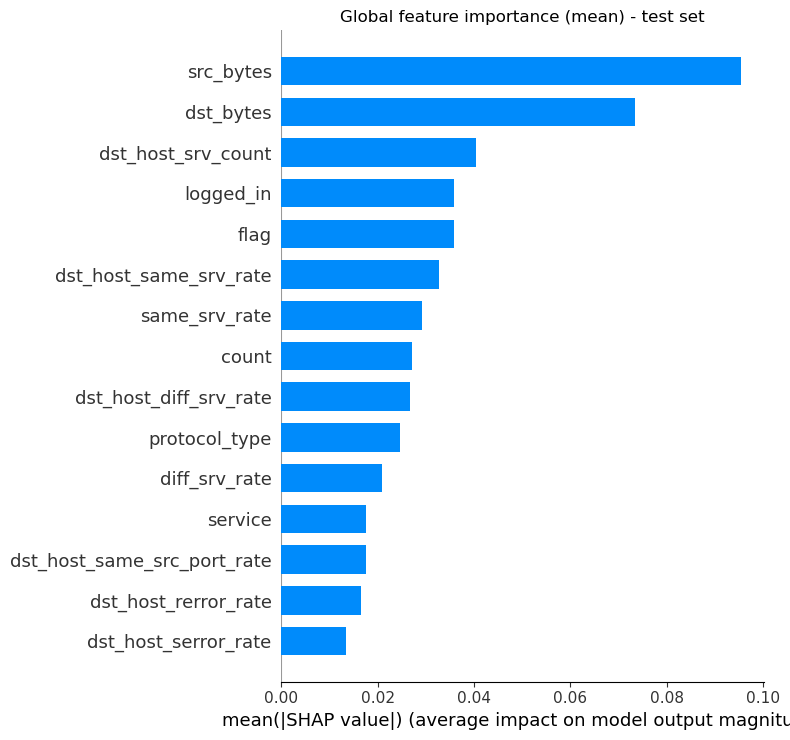

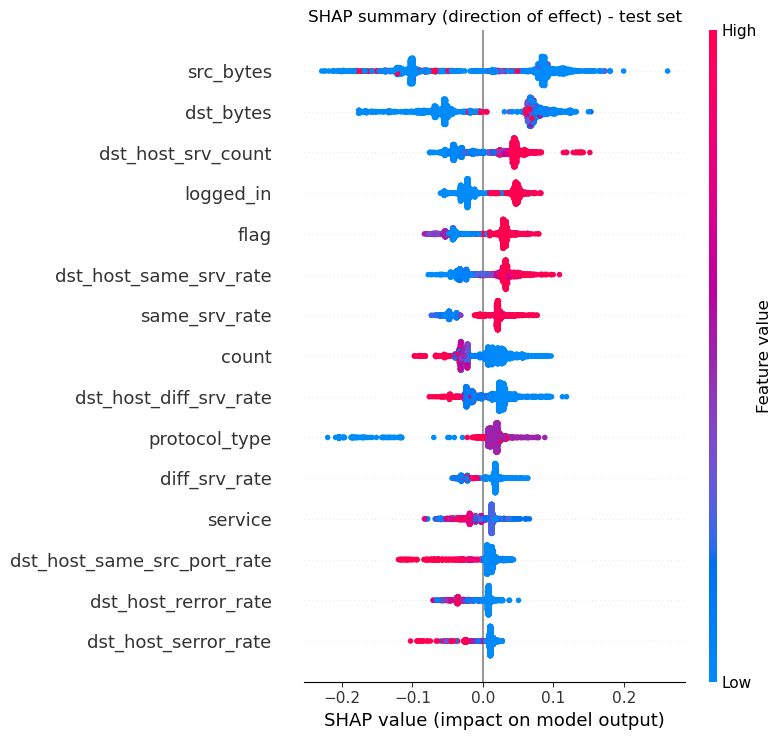

In [ ]:
sample_n = min(2000, len(X_test))
X_shap = X_test.sample(n=sample_n, random_state=42)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap)

if isinstance(shap_values, list):
    shap_values_attack = shap_values[1]
elif shap_values.ndim == 3:
    shap_values_attack = shap_values[:, :, 1]
else:
    shap_values_attack = shap_values

shap.summary_plot(shap_values_attack, X_shap, plot_type="bar", show=False, max_display=15)
plt.title("Global feature importance (mean) - test set")
plt.tight_layout()
plt.show()

shap.summary_plot(shap_values_attack, X_shap, show=False, max_display=15)
plt.title("SHAP summary (direction of effect) - test set")
plt.tight_layout()
plt.show()